# Zhang et al. 2021 — RCC (Kidney) · 02 Manifold

scFates principal **curve** (non-branching topology; verified below) → biologically-motivated root
at the Gast/pSom-high developmental origin → pseudotime → milestones. The topology choice (curve vs
tree) is read off the embedding: an aggressive PPT tree over-fits this compact near-round cloud into
dozens of spurious forks (no coherent two-armed divergence), so a single curve is the honest fit.
Fold-freeness is checked against an independent (PCA/diffmap) embedding.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

## Load processed manifold; score signatures + graph-smooth

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
from numpy.linalg import svd
u,s,vt = svd(c0, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth signatures for geography (3 propagation steps over kNN connectivities)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 11218 cells
UMAP aspect ratio (major/minor std): 1.21
Gast: 74/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present


## Topology test — tree over-fits a near-round cloud

An aggressive PPT tree is fit purely as a diagnostic. A genuine Gast/pSom bifurcation would produce
**one** dominant fork with two arms carrying opposite module loadings; dozens of tiny forks with no
module contrast is the signature of a single continuous cloud, not a Y.

In [6]:
ad_tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_tree, method='ppt', Nodes=150, use_rep='X_umap',
                ppt_lambda=100, ppt_sigma=0.1, seed=SEED, plot=False)
Bt = np.asarray(ad_tree.uns['graph']['B'])
tips_t = int(((Bt>0).sum(0)==1).sum()); forks_t = int(((Bt>0).sum(0)>=3).sum())
print(f'aggressive PPT tree: {tips_t} tips, {forks_t} forks (dozens of specks = over-fit, not a bifurcation)')
# per-leiden-lobe signature means: no Gast-high arm anywhere -> no cross-repression bifurcation
print('\nper-lobe smoothed developmental means (Gast never positive -> no Gast arm):')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())

aggressive PPT tree: 35 tips, 33 forks (dozens of specks = over-fit, not a bifurcation)

per-lobe smoothed developmental means (Gast never positive -> no Gast arm):
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0     -0.0318   0.0809   -0.0581
1     -0.0318   0.0762   -0.0528


## Scope decision — keep whole manifold

Cycling is negligible and the Crest-high (terminal) cells are not confined to one histology, so the
developmental axis is not confounded by a proliferation split. No sub-region scoping needed.

In [8]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'subtype'].value_counts(normalize=True).round(2).to_dict()
print('Crest-high decile across histologies:', frac, '-> not confined; keep whole manifold')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.68
  Crest_sm vs Gast_sm: r = +0.46
  Crest_sm vs pSom_sm: r = -0.91
Crest-high decile across histologies: {'Clear-Cell RCC': 0.53, 'Chromophobe RCC': 0.47} -> not confined; keep whole manifold


## Principal curve + fold diagnostic (independent-embedding check)

In [10]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.71 (>1 = fold-free)


## Root at the developmental origin; pseudotime

In [12]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(highest Gast+pSom, lowest Crest = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho, smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
print('(near-zero rho: modules present but weakly resolved spatially -> single diffuse axis)')

tip 0: Gast=-0.0300 pSom=+0.0835 Crest=-0.0636
tip 2: Gast=-0.0309 pSom=+0.0719 Crest=-0.0501
derived root = tip 0 (highest Gast+pSom, lowest Crest = developmental origin)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.110 p=1.3e-31
  pSom_sm: rho=-0.330 p=7.3e-284
  Crest_sm: rho=+0.583 p=0.0e+00
(near-zero rho: modules present but weakly resolved spatially -> single diffuse axis)


## Independent-embedding fold confirmation (diffmap)

In [14]:
sc.tl.diffmap(sub)
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=16).fit(sub.obsm['X_pca_harmony'][:,:20])
idx = nn.kneighbors(sub.obsm['X_pca_harmony'][:,:20], return_distance=False)[:,1:]
tt = sub.obs['t'].values; tn = (tt-tt.min())/(tt.max()-tt.min())
local = np.abs(tn[idx]-tn[:,None]).mean(1)
print(f'independent-embedding (Harmony-PCA nbrs) pseudotime smoothness: '
      f'mean local |dt|={local.mean():.3f}, frac>0.3={np.mean(local>0.3):.3f} (low = fold-free)')

independent-embedding (Harmony-PCA nbrs) pseudotime smoothness: mean local |dt|=0.077, frac>0.3=0.029 (low = fold-free)


## Orientation (`X_umap_lin`, pseudotime left->right) + save

In [16]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# rotate cloud so its principal axis is horizontal, then flip so low pt -> left
c0 = xy - xy.mean(0); _,_,vt = np.linalg.svd(c0, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c0 @ Rm.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: principal-axis rotation; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: principal-axis rotation; corr(x_lin, pseudotime) = +0.93


saved manifold.h5ad + manifold.pdf


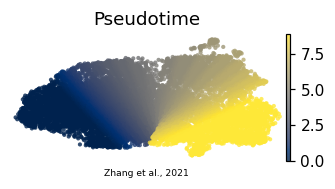

In [17]:
ren = {c: f'M{i}' for i,c in enumerate(sub.obs['milestones'].cat.categories)}
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')